# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

### Importing the requirements

In [ ]:
from project3_fish_stock import (fibonacci, FishStock, PriceModel, RiskAssessor, analyse_scenario, make_plots)
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

## Fibonacci baseline

In [10]:
print(fibonacci(15))

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377]


## Fish stock and price classes

In [4]:
fish = FishStock(initial_stock=4000, growth_rate=0.4, carrying_capacity=10000)
prices = PriceModel(start_price=12000, min_price=9000, max_price=16000)
risk = RiskAssessor(low_threshold=0.10, high_threshold=0.25)
print("Theoretical MSY (tonnes/week):", fish.theoretical_msy)

Theoretical MSY (tonnes/week): 1000.0


## Descriptive statistics, risk and harvest scenarios
I calculated revenue by multiplying the fish harvested in tonnes by 1,000 to convert it into kilograms, then multiplying by the price per kilogram in UGX. The CV limits were just examples. I used Monte Carlo simulation to test 1,000 possible yearly price changes. The 5th percentile shows the revenue level that only 5% of the simulated results fell below, while VaR focuses on possible losses.

In [5]:
results = [analyse_scenario(fish, prices, risk, h, weeks=52, paths=1000, seed=2026) for h in (0.05, 0.10, 0.20, 0.30)]
for r in results:
    print(f"h={r['harvest_rate']:.0%}: final stock={r['final_stock']:,.1f} tonnes; annual revenue={r['annual_revenue']:,.0f} UGX; CV={r['revenue_summary']['cv']:.3f}; risk={r['risk_class']}; 5% revenue quantile={r['revenue_p5']:,.0f} UGX")

h=5%: final stock=8,750.0 tonnes; annual revenue=270,218,779,681 UGX; CV=0.177; risk=Moderate; 5% revenue quantile=215,367,475,409 UGX
h=10%: final stock=7,500.0 tonnes; annual revenue=464,806,496,490 UGX; CV=0.165; risk=Moderate; 5% revenue quantile=370,701,604,113 UGX
h=20%: final stock=5,000.0 tonnes; annual revenue=631,911,796,594 UGX; CV=0.126; risk=Moderate; 5% revenue quantile=506,175,185,753 UGX
h=30%: final stock=2,503.7 tonnes; annual revenue=523,996,527,791 UGX; CV=0.120; risk=Moderate; 5% revenue quantile=425,809,865,398 UGX


In [6]:
for key, value in results[1]["revenue_summary"].items():
    print(key, value)
print("Variance is in UGX squared; a fixed threshold such as 50,000 lacks a scale-independent interpretation.")

mean 8938586470.957455
median 8889209105.773304
variance 2.187224699928608e+18
std_dev 1478926874.4358554
cv 0.16545422245911778
Variance is in UGX squared; a fixed threshold such as 50,000 lacks a scale-independent interpretation.


## 7. Visualisations

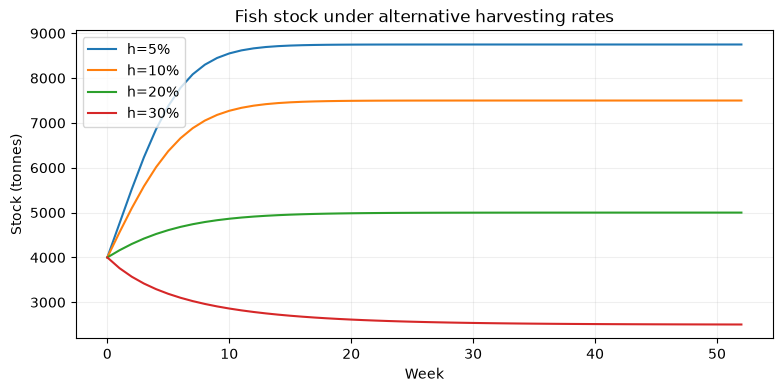

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
for r in results:
    ax.plot(r["stock"], label=f"h={r['harvest_rate']:.0%}")
ax.set(xlabel="Week", ylabel="Stock (tonnes)", title="Fish stock under alternative harvesting rates")
ax.legend(); ax.grid(alpha=.2); plt.show()

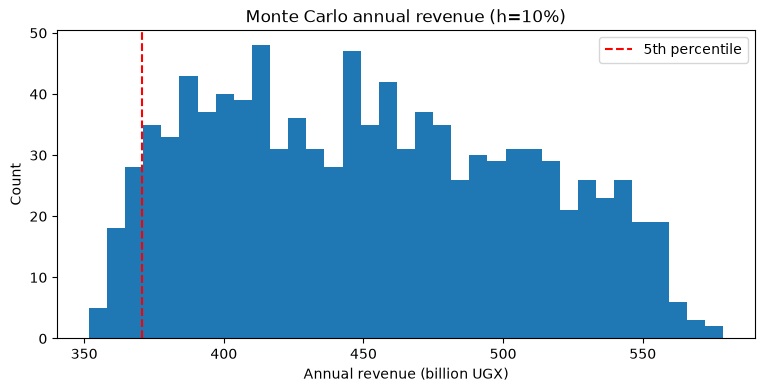

In [8]:
base = results[1]
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(base["annual_revenues"]/1e9, bins=35)
ax.axvline(base["revenue_p5"]/1e9, color="red", linestyle="--", label="5th percentile")
ax.set(xlabel="Annual revenue (billion UGX)", ylabel="Count", title="Monte Carlo annual revenue (h=10%)")
ax.legend(); plt.show()

## Findings & Limitations

Understand that higher harvesting rates do not necessarily mean better long-term returns. Lower harvesting rates generally allow fish stocks to recover, while excessive harvesting can reduce the fish population and affect future income.

I also considered Maximum Sustainable Yield (MSY), which provides a benchmark for harvesting fish without continuously reducing the stock. The Fibonacci approach was unrealistic because it assumes fish populations keep growing without considering food shortages, environmental conditions or harvesting.

For revenue risk, I used the coefficient of variation (CV) because it measures fluctuations relative to average revenue, unlike variance, which only shows the spread in squared units. The fifth-percentile revenue helped me understand the lower end of possible earnings, where approximately 5% of simulated outcomes fall below that amount.

However, the Monte Carlo simulation mainly considered changes in fish prices, leaving out other risks such as weather, fishing costs, stock depletion and market disruptions. Another limitation is that the fish population parameters and prices were illustrative rather than actual Lake Victoria measurements.